# Measuring overlap through event concurrency

The first quantity records whether event $i$ uses the return at time $t,$ and the second counts all active events:

$$
I_{ti}=mathbf 1\{s_i\leq t\leq e_i\},\qquad
c_t=\sum_{i=1}^{n} I_{ti}.
$$

Here, $i\in\{1,\ldots,n\}$ labels events; $t$ labels a price interval; $s_i$ and $e_i$ are event start and end times. $I_{ti}\in\{0,1\}$ is the event indicator; $\mathbf 1\{\cdot\}$ equals one when its condition is true; $c_t$ is concurrency.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("07_overlapping_information_weights");
using CSV, Printf
using RiskLabAI.Data: daily_volatility_with_log_returns,symmetric_cusum_filter,cusum_filter_events_dynamic_threshold,vertical_barrier,triple_barrier,meta_labeling,calculate_t_value_linear_regression,find_trend_using_trend_scanning
raw = load_binance()
data_path = dataset_path("binance_btcusdt")
@assert isfile(data_path)
close_index,close_prices = raw.time,raw.close
log_price = log.(close_prices)
price_positions = Dict(time=>position for (position,time) in enumerate(close_index))
violet = "#C084FC"

function count_histogram!(figure,values,bins;color,label=false,alpha=.75)
    edges = collect(range(minimum(values),maximum(values);length=bins+1))
    counts = [count(value->edges[index]<=value && (value<edges[index+1] || index==bins && value==edges[end]),values) for index in 1:bins]
    bar!(figure,(edges[1:end-1].+edges[2:end])./2,counts;bar_width=diff(edges),color,fillalpha=alpha,linecolor=color,label)
    ylims!(figure,0.,1.1max(maximum(counts),last(ylims(figure))))
    return DataFrame(left=edges[1:end-1],right=edges[2:end],count=counts)
end

function box_summary!(figure,groups,colors)
    for (index,values) in enumerate(groups)
        lower,middle,upper = quantile(values,[.25,.5,.75])
        spread = upper-lower
        bottom = minimum(values[values.>=lower-1.5spread])
        top = maximum(values[values.<=upper+1.5spread])
        plot!(figure,Shape([index-.25,index+.25,index+.25,index-.25],[lower,lower,upper,upper]);color=colors[index],fillalpha=.65,linecolor=palette.text,label=false)
        plot!(figure,[index-.25,index+.25],[middle,middle];color=palette.text,label=false)
        plot!(figure,[index,index],[bottom,lower];color=palette.text,label=false)
        plot!(figure,[index,index],[upper,top];color=palette.text,label=false)
        for height in (bottom,top)
            plot!(figure,[index-.12,index+.12],[height,height];color=palette.text,label=false)
        end
    end
    return figure
end
using RiskLabAI.Data: calculate_average_uniqueness,calculate_time_decay,expand_label_for_meta_labeling,sample_weight_absolute_return_meta_labeling,sequential_bootstrap
minute_close = copy(close_prices)
resampled = combine(groupby(DataFrame(time=floor.(raw.time,Minute(15)),price=raw.close),:time;sort=true),:price=>last=>:close)
close_index,close_prices = resampled.time,resampled.close
log_price = log.(close_prices)
price_positions = Dict(time=>position for (position,time) in enumerate(close_index))
span = 100
volatility = daily_volatility_with_log_returns(close_index,close_prices;span)
volatility_lookup = Dict(zip(volatility.index,volatility.volatility))

function dynamic_threshold_events(multiplier)
    selected = findall(isfinite,volatility.volatility)
    positions = [price_positions[volatility.index[index]] for index in selected]
    aligned = vcat(first(positions)-1,positions)
    return cusum_filter_events_dynamic_threshold(close_index[aligned],log_price[aligned],vcat(NaN,multiplier.*volatility.volatility[selected]))
end
event_times = dynamic_threshold_events(1.)
vertical_times = vertical_barrier(close_index,event_times,1)
ending_lookup = Dict(zip(vertical_times.event,vertical_times.barrier))
event_times = [time for time in event_times if haskey(ending_lookup,time) && isfinite(get(volatility_lookup,time,NaN))]
event_ends = [ending_lookup[time] for time in event_times]
start_positions,end_positions = [price_positions[time] for time in event_times],[price_positions[time] for time in event_ends]
indicator_matrix = Int[time>=start && time<=ending for time in close_index,(start,ending) in zip(event_times,event_ends)]
event_duration = vec(sum(indicator_matrix;dims=1))
matrix_concurrency = vec(sum(indicator_matrix;dims=2))
active_concurrency = matrix_concurrency[matrix_concurrency.>0]
library_concurrency = expand_label_for_meta_labeling(close_index,event_times,event_ends,event_times);


## From Event Spans to Concurrent Information

In [2]:
data_provenance = DataFrame("Field"=>["Archive","Provider","Public access","Market","Minute records","Analysis interval","Analysis records","Event rule","Event horizon","Events"],"Value"=>["BTCUSDT-1m-2021-01.zip","Binance Data Vision","Direct public download","Bitcoin quoted in USDT",string(length(minute_close)),"Fifteen minutes",string(length(close_prices)),"Changing cumulative threshold equal to estimated one-day volatility","One day",string(length(event_times))])
concurrency_summary = DataFrame("Quantity"=>["Events","Active fifteen-minute records","Records used by every event","Largest concurrency","Middle concurrency while active","Active records with overlap"],"Value"=>[length(event_times),count(>(0),matrix_concurrency),first(event_duration),maximum(active_concurrency),median(active_concurrency),mean(active_concurrency.>1)])
group_names = ["No active event","One event","Two or three events","Four to six events","Seven or more events"]
counts = [count(==(0),matrix_concurrency),count(==(1),matrix_concurrency),count(value->2<=value<=3,matrix_concurrency),count(value->4<=value<=6,matrix_concurrency),count(>=(7),matrix_concurrency)]
concurrency_distribution = DataFrame("Concurrency group"=>group_names,"Fifteen-minute records"=>counts,"Share"=>counts./length(close_prices))
save_table(data_provenance,paths,"data_provenance";caption="Public data and event construction used in Chapter 6.",label="tab:chapter6-data-provenance")
save_table(concurrency_summary,paths,"concurrency_summary";caption="Concurrency summary for the public January event spans.",label="tab:chapter6-concurrency-summary")
save_table(concurrency_distribution,paths,"concurrency_distribution";caption="Distribution of concurrent events across fifteen-minute records.",label="tab:chapter6-concurrency-distribution")
save_data(DataFrame(time=close_index,close=close_prices,concurrency=matrix_concurrency),paths,"resampled_price_concurrency")
save_data(DataFrame(start=event_times,ending=event_ends,records=event_duration),paths,"one_day_event_spans")
save_data(DataFrame(time=volatility.index,volatility=volatility.volatility),paths,"fifteen_minute_volatility")
save_data(DataFrame(indicator_matrix,:auto),paths,"indicator_matrix");


Row,Field,Value
,String,String
1,Archive,BTCUSDT-1m-2021-01.zip
2,Provider,Binance Data Vision
3,Public access,Direct public download
4,Market,Bitcoin quoted in USDT
5,Minute records,44640
6,Analysis interval,Fifteen minutes
7,Analysis records,2976
8,Event rule,Changing cumulative threshold equal to estimated one-day volatility
9,Event horizon,One day


Row,Quantity,Value
,String,Float64
1,Events,133.0
2,Active fifteen-minute records,2795.0
3,Records used by every event,97.0
4,Largest concurrency,12.0
5,Middle concurrency while active,4.0
6,Active records with overlap,0.918426


Row,Concurrency group,Fifteen-minute records,Share
,String,Int64,Float64
1,No active event,181,0.0608199
2,One event,228,0.0766129
3,Two or three events,921,0.309476
4,Four to six events,1014,0.340726
5,Seven or more events,632,0.212366


Pairwise overlap counts the price intervals used by both events, and it cannot exceed the shorter event span:

$$
O_{ij}=\sum_t I_{ti}I_{tj},\qquad
0\leq O_{ij}\leq \min\{L_i,L_j\},\qquad
L_i=\sum_t I_{ti}.
$$

Here, $O_{ij}$ is the overlap count for events $i$ and $j$; $I_{ti},I_{tj}$ are their indicators at time $t.$ $L_i$ and $L_j$ are event lengths measured in price intervals; $\min$ selects the smaller length.

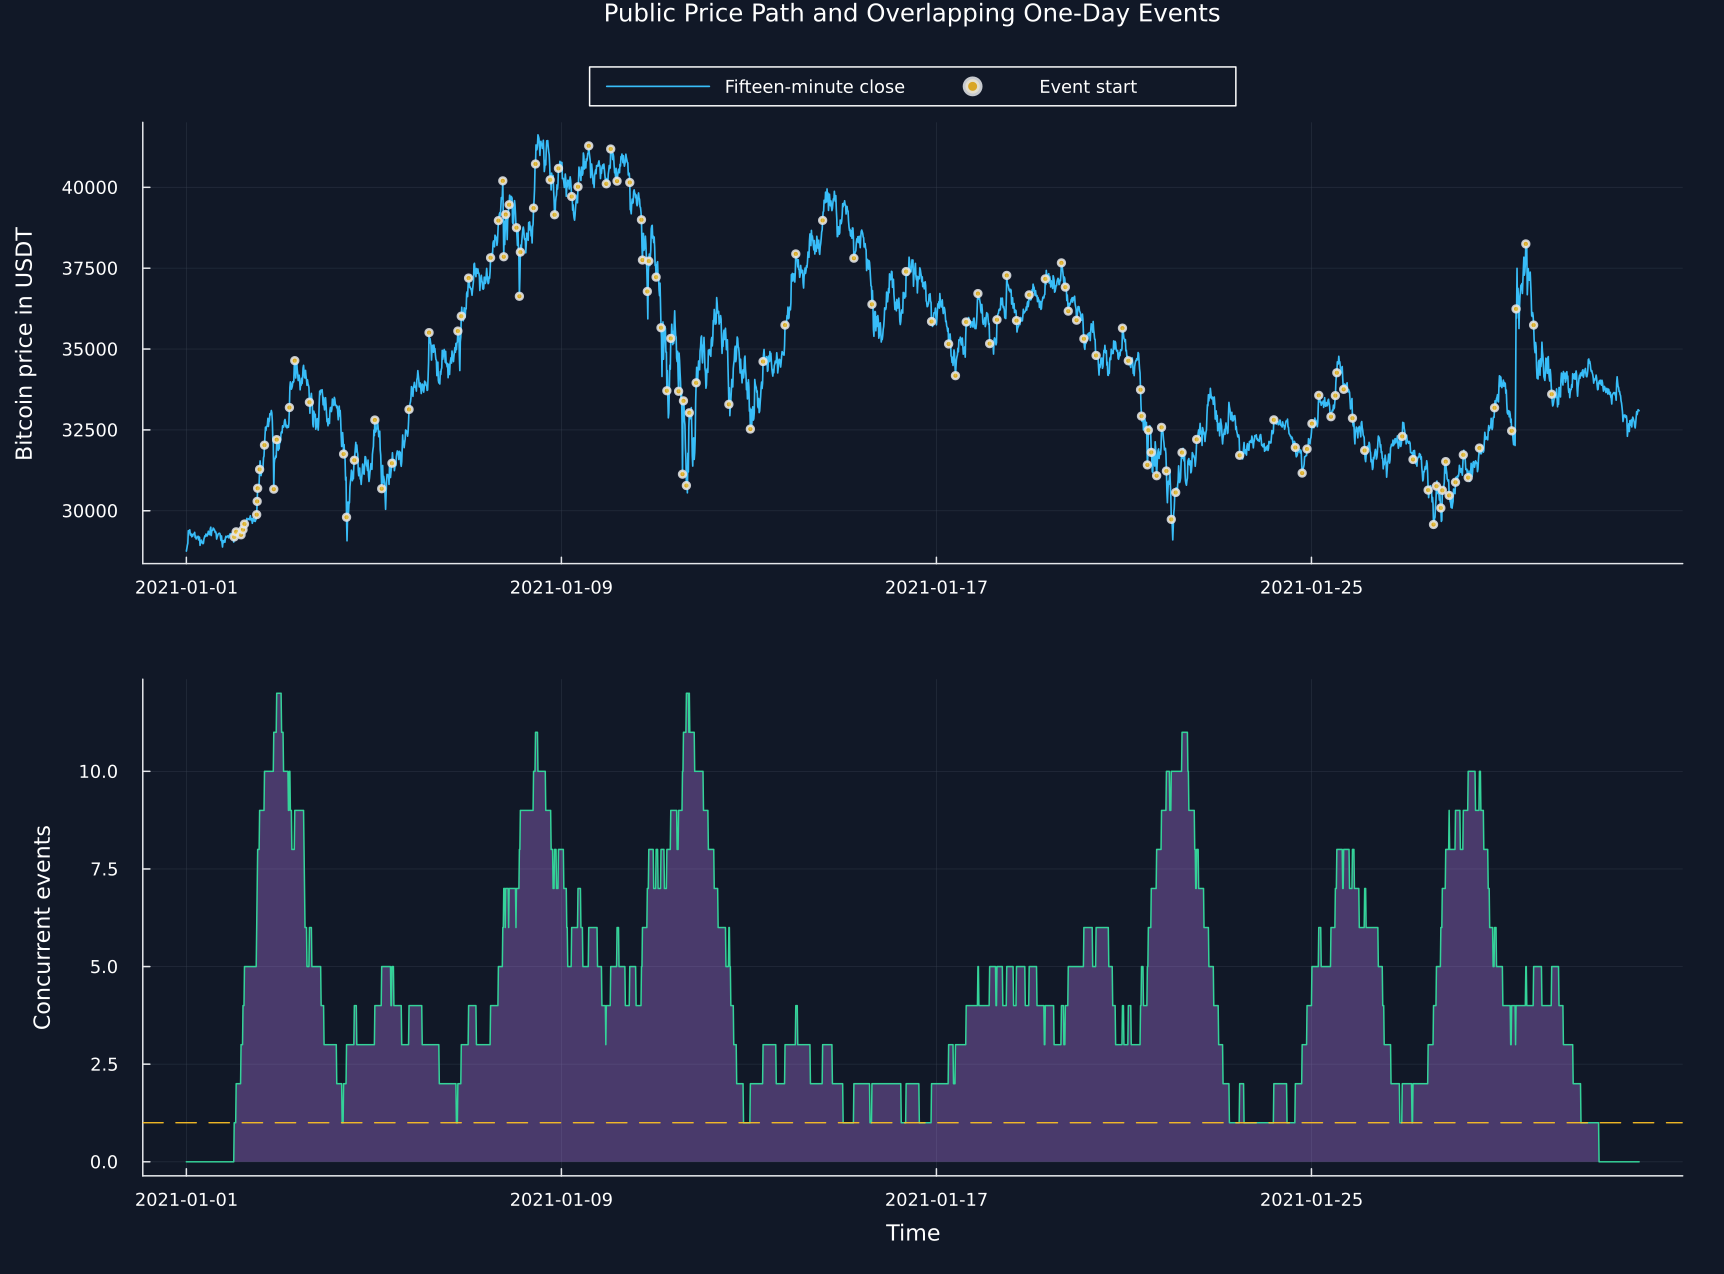

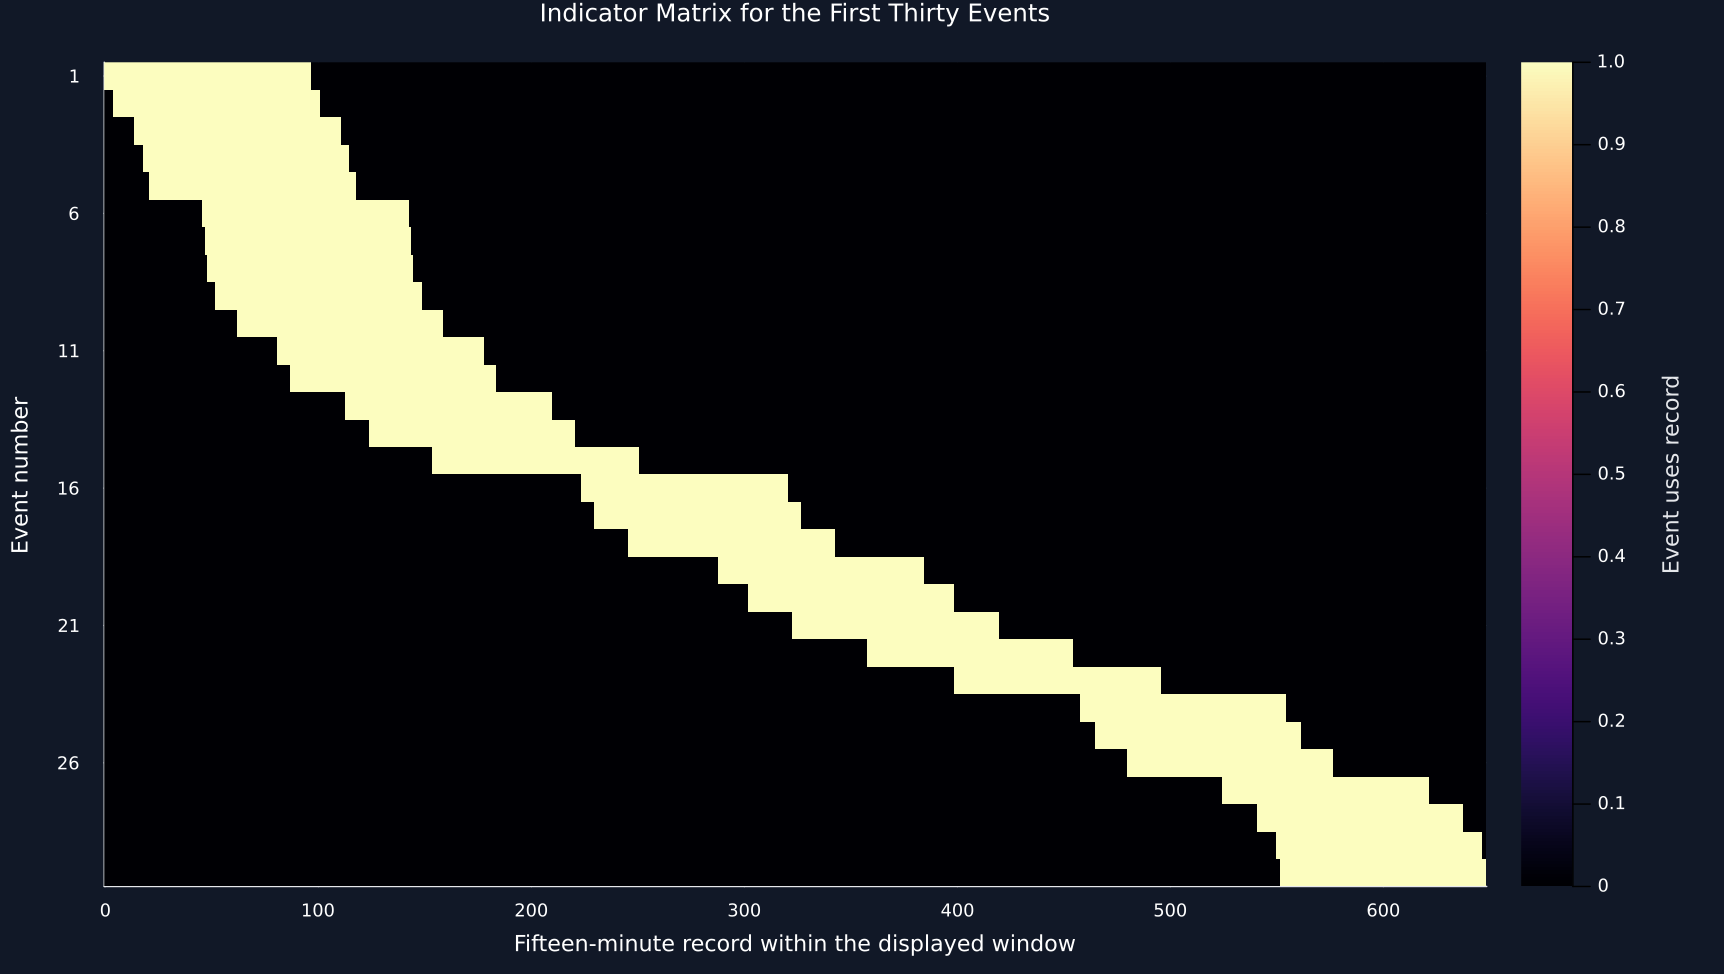

In [3]:
overlap_matrix = transpose(indicator_matrix)*indicator_matrix
p1 = plot(close_index,close_prices;color=palette.cyan,linewidth=1.1,label="Fifteen-minute close",ylabel="Bitcoin price in USDT",title="Public Price Path and Overlapping One-Day Events",legend=:outertop,legend_column=2)
scatter!(p1,event_times,close_prices[start_positions];color=palette.amber,markersize=2.5,alpha=.85,label="Event start")
p2 = plot(close_index,matrix_concurrency;color=palette.green,linewidth=1.,fillrange=0,fillcolor=violet,fillalpha=.32,ylabel="Concurrent events",xlabel="Time",label=false)
hline!(p2,[1.];color=palette.amber,linewidth=.9,linestyle=:dash,label=false)
save_figure(plot(p1,p2;layout=(2,1),link=:x,size=(1150,850)),paths,"event_concurrency")
displayed_events = 1:min(30,length(event_times))
displayed_positions = minimum(start_positions[displayed_events]):maximum(end_positions[displayed_events])
displayed_rows = indicator_matrix[displayed_positions,displayed_events]
figure = heatmap(0:size(displayed_rows,1)-1,collect(displayed_events),transpose(displayed_rows);color=:magma,clims=(0,1),yflip=true,colorbar_title="Event uses record",yticks=1:5:length(displayed_events),title="Indicator Matrix for the First Thirty Events",xlabel="Fifteen-minute record within the displayed window",ylabel="Event number",size=(1150,650))
save_figure(figure,paths,"overlap_indicator")
save_data(DataFrame(overlap_matrix,:auto),paths,"pairwise_overlap");


## Tests

In [4]:
aligned_matrix_concurrency = [matrix_concurrency[price_positions[time]] for time in library_concurrency.index]
@assert length(minute_close)==44640
@assert length(close_prices)==2976
@assert length(event_times)==133
@assert length(unique(event_duration))==1
@assert first(event_duration)==97
@assert library_concurrency.concurrency==aligned_matrix_concurrency
@assert maximum(matrix_concurrency)==12
@assert count(>(0),matrix_concurrency)==2795
@assert mean(active_concurrency.>1)>.90
@assert diag(overlap_matrix)==event_duration
@assert all(overlap_matrix.>=0)
@assert all(overlap_matrix.<=min.(event_duration,transpose(event_duration)))
@assert sum(concurrency_distribution[!,"Fifteen-minute records"])==length(close_prices)
@assert isapprox(sum(concurrency_distribution.Share),1.)
